In [1]:

# Task 1: Exploratory Data Analysis on Retail Sales

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the retail sales dataset
df = pd.read_csv("../dataset/retail_sales_dataset.csv")

# Display first 5 records
df.head()


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:

# Check dataset dimensions
print("Number of Rows and Columns:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())


Number of Rows and Columns: (1000, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Records: 0


The dataset contains 1,000 retail transactions and 9 columns.
There are no missing values or duplicate records.
The dataset includes customer demographics, product categories,
quantity, price per unit, and total amount.
Therefore, the dataset is ready for further exploratory data analysis.

In [4]:

# Descriptive Statistics

# Select numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Calculate Mean
print("MEAN:")
print(df[numerical_columns].mean())

# Calculate Median
print("\nMEDIAN:")
print(df[numerical_columns].median())

# Calculate Mode
print("\nMODE:")
print(df[numerical_columns].mode().iloc[0])

# Calculate Standard Deviation
print("\nSTANDARD DEVIATION:")
print(df[numerical_columns].std())


MEAN:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

MEDIAN:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

MODE:
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

STANDARD DEVIATION:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


MONTHLY SALES:
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


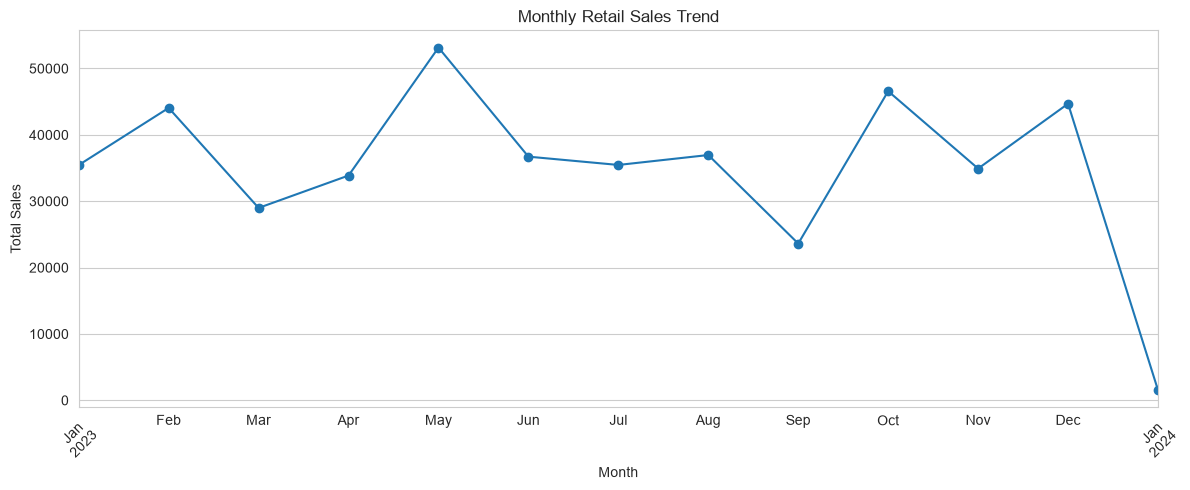

In [5]:

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Extract month and calculate monthly sales
df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Total Amount'].sum()

# Display monthly sales
print("MONTHLY SALES:")
print(monthly_sales)

# Plot monthly sales trend
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


QUARTERLY SALES:
Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64


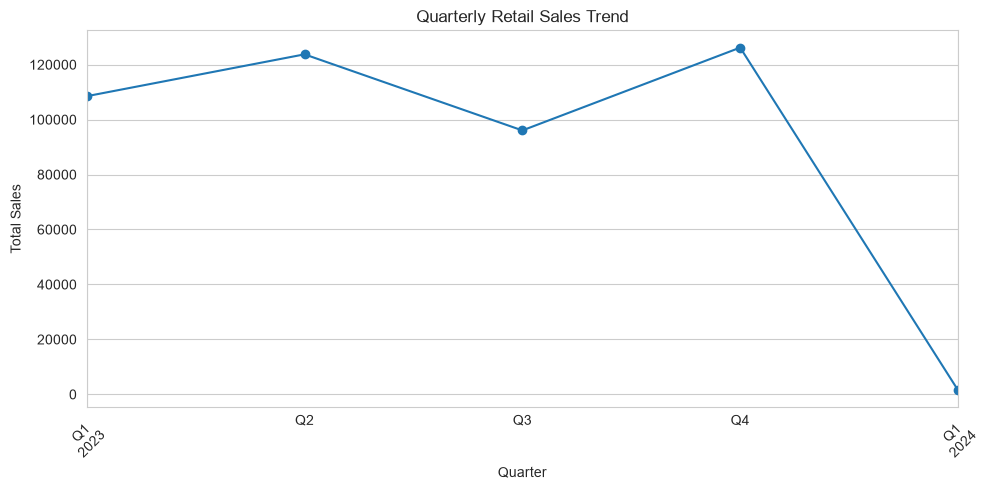

In [6]:

# Calculate quarterly sales
df['Quarter'] = df['Date'].dt.to_period('Q')

quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

print("QUARTERLY SALES:")
print(quarterly_sales)

# Plot quarterly sales trend
plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind='line', marker='o')

plt.title('Quarterly Retail Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Monthly and quarterly analysis shows that retail sales
fluctuate throughout the year. May recorded the highest
monthly sales in 2023, while Q4 recorded the highest
quarterly sales. These trends can help businesses plan
inventory and promotional activities.

CUSTOMER AGE GROUP DISTRIBUTION:
Age Group
Below 20     63
20-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64


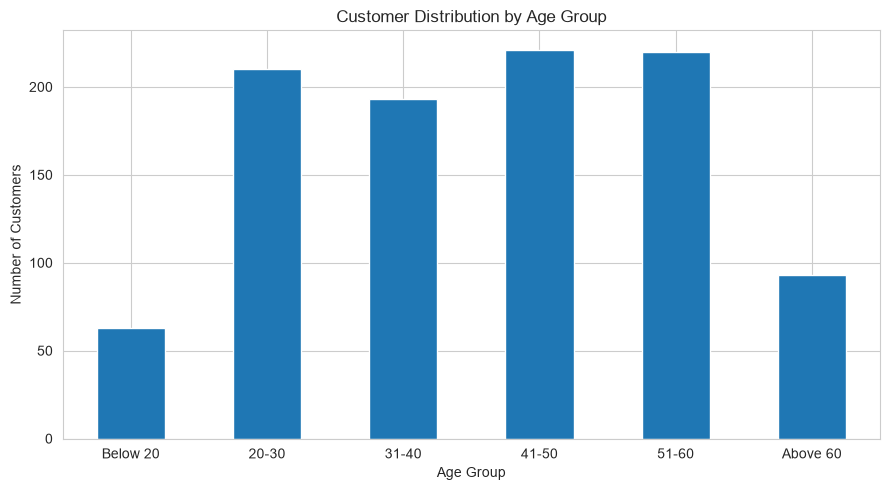


GENDER DISTRIBUTION:
Gender
Female    510
Male      490
Name: count, dtype: int64


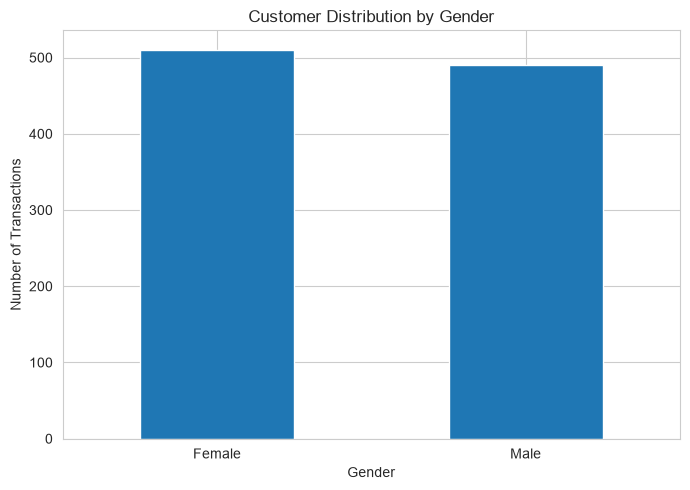

In [7]:

# Customer Demographics Analysis

# Create age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '20-30', '31-40',
            '41-50', '51-60', 'Above 60']
)

# Age group distribution
age_distribution = df['Age Group'].value_counts().sort_index()

print("CUSTOMER AGE GROUP DISTRIBUTION:")
print(age_distribution)

# Plot age group distribution
plt.figure(figsize=(9, 5))
age_distribution.plot(kind='bar')

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Gender distribution
gender_distribution = df['Gender'].value_counts()

print("\nGENDER DISTRIBUTION:")
print(gender_distribution)

# Plot gender distribution
plt.figure(figsize=(7, 5))
gender_distribution.plot(kind='bar')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Customer demographics analysis shows that customers
aged 41-50 form the largest age group. Customers aged
below 20 form the smallest group. Female transactions
are slightly higher than male transactions.

This information can help businesses understand their
customer base and plan targeted marketing campaigns.

REVENUE BY PRODUCT CATEGORY:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


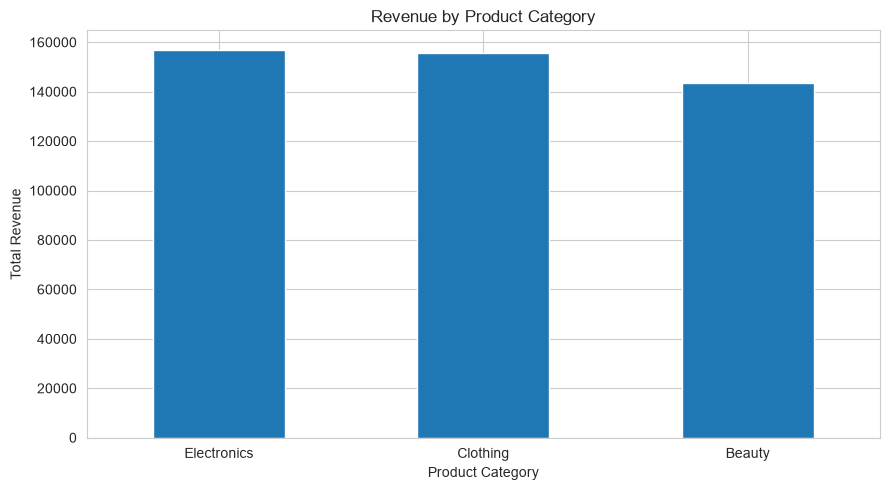


QUANTITY SOLD BY CATEGORY:
Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


In [8]:

# Product Category Analysis

# Calculate total sales by product category
category_sales = df.groupby('Product Category')['Total Amount'].sum()

print("REVENUE BY PRODUCT CATEGORY:")
print(category_sales.sort_values(ascending=False))

# Plot category-wise revenue
plt.figure(figsize=(9, 5))
category_sales.sort_values(ascending=False).plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Calculate quantity sold by category
category_quantity = df.groupby('Product Category')['Quantity'].sum()

print("\nQUANTITY SOLD BY CATEGORY:")
print(category_quantity.sort_values(ascending=False))


Product category analysis shows that Electronics
generates the highest revenue, followed closely by
Clothing. Beauty generates comparatively lower revenue.

The business can maintain stock in Electronics and
Clothing while exploring promotional offers to improve
Beauty category sales.

CORRELATION MATRIX:
                Transaction ID       Age  Quantity  Price per Unit  \
Transaction ID        1.000000  0.065191 -0.026623       -0.060837   
Age                   0.065191  1.000000 -0.023737       -0.038423   
Quantity             -0.026623 -0.023737  1.000000        0.017501   
Price per Unit       -0.060837 -0.038423  0.017501        1.000000   
Total Amount         -0.075034 -0.060568  0.373707        0.851925   

                Total Amount  
Transaction ID     -0.075034  
Age                -0.060568  
Quantity            0.373707  
Price per Unit      0.851925  
Total Amount        1.000000  


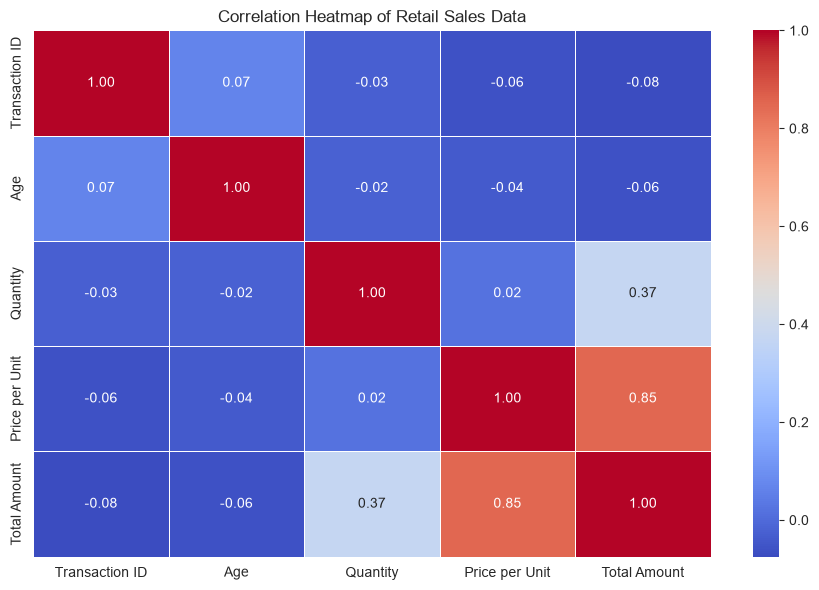

In [9]:

# Correlation Analysis

# Select numerical columns
numerical_data = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

print("CORRELATION MATRIX:")
print(correlation_matrix)

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Retail Sales Data')
plt.tight_layout()
plt.show()


The correlation heatmap shows a strong positive
correlation (0.85) between Price per Unit and Total Amount.
Quantity has a moderate positive correlation (0.37)
with Total Amount.

Age has a very weak correlation with Total Amount.
This indicates that transaction value is more closely
associated with price and quantity than customer age.

AVERAGE TRANSACTION VALUE BY GENDER:
Gender
Female    456.549020
Male      455.428571
Name: Total Amount, dtype: float64


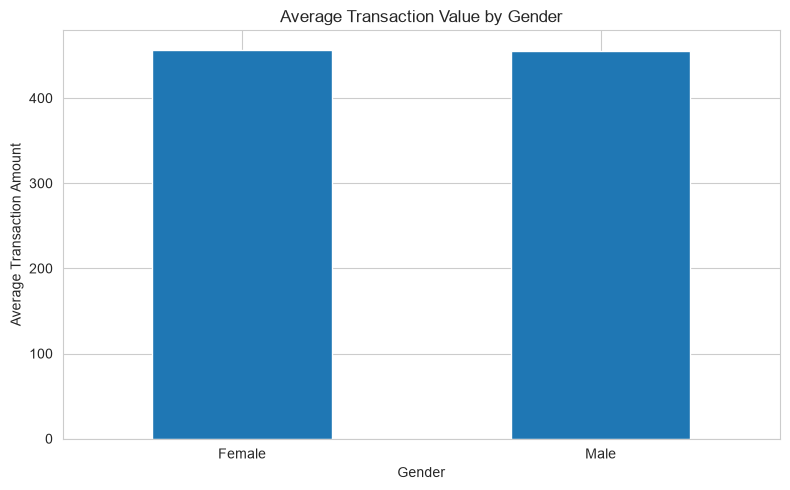

In [10]:

# Additional Analysis: Average Transaction Value by Gender

gender_sales = df.groupby('Gender')['Total Amount'].mean()

print("AVERAGE TRANSACTION VALUE BY GENDER:")
print(gender_sales)

plt.figure(figsize=(8, 5))

gender_sales.plot(kind='bar')

plt.title('Average Transaction Value by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


The average transaction value of Female and Male
customers is almost equal. Both groups show similar
spending patterns. Therefore, marketing strategies
should consider product preferences rather than
focusing only on gender.

## Conclusion and Business Recommendations

The Exploratory Data Analysis of 1,000 retail transactions helped identify sales trends, customer demographics, product category performance, and transaction patterns.

### Key Findings
1. May 2023 recorded the highest monthly sales.
2. Q4 2023 recorded the highest quarterly sales.
3. Customers aged 41–50 formed the largest age group.
4. Electronics generated the highest category revenue.
5. Price per Unit showed a strong positive correlation with Total Amount.
6. Female and Male customers had almost equal average transaction values.

### Business Recommendations

1. **Inventory Management:** Maintain sufficient stock of Electronics and Clothing because they generate higher revenue.
2. **Targeted Marketing:** Develop suitable promotional campaigns for customers aged 41–60, who represent a large customer group.
3. **Seasonal Planning:** Plan inventory and promotional campaigns based on monthly and quarterly sales trends.
4. **Product Pricing:** Monitor product prices and quantities to understand their relationship with transaction revenue.
5. **Category Improvement:** Introduce promotional offers for the Beauty category to explore opportunities for increasing revenue.

### Dataset Limitation

The dataset does not contain individual product names. Therefore, the analysis covers product categories instead of the top 10 individual best-selling products.

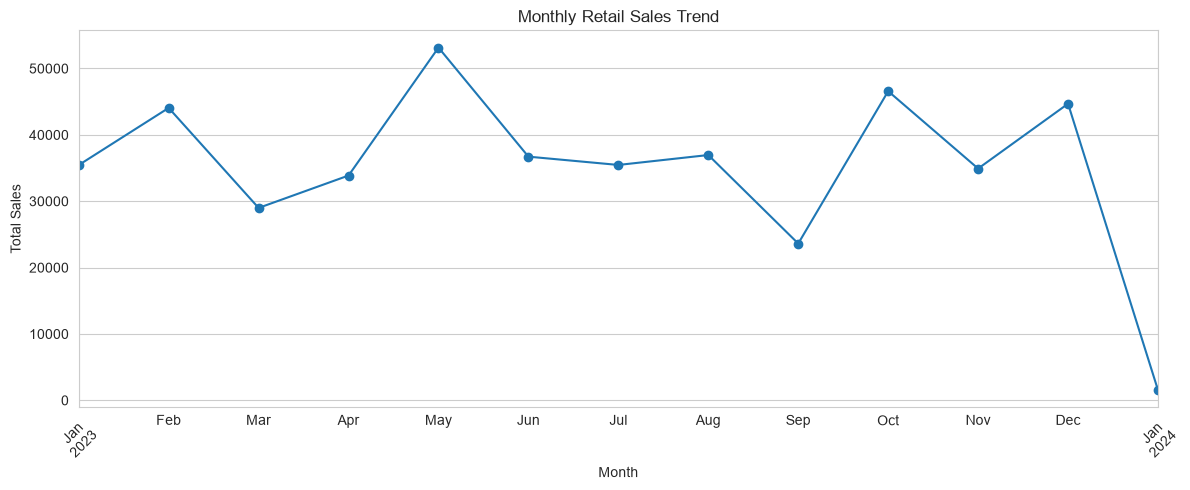

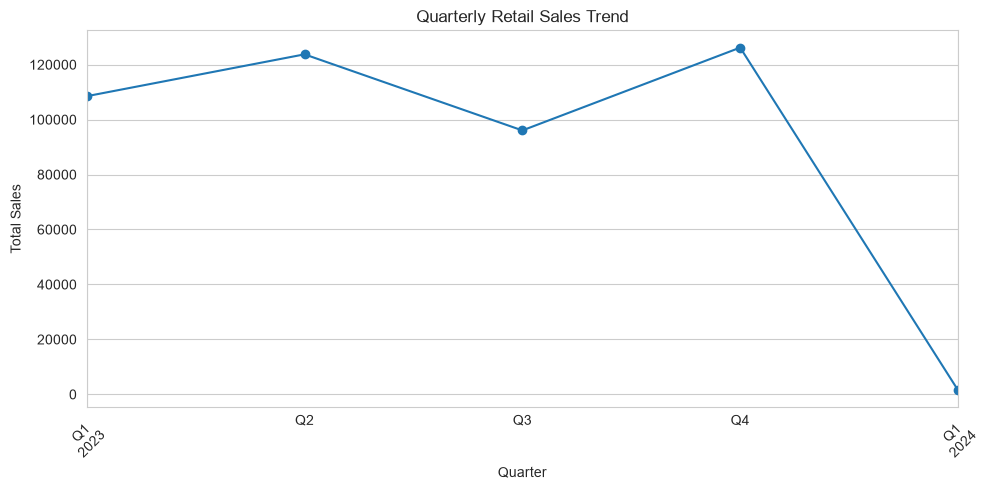

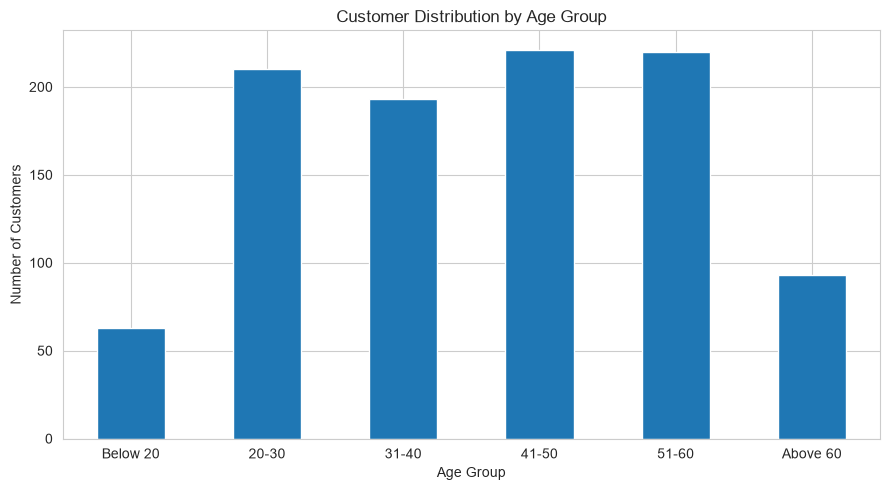

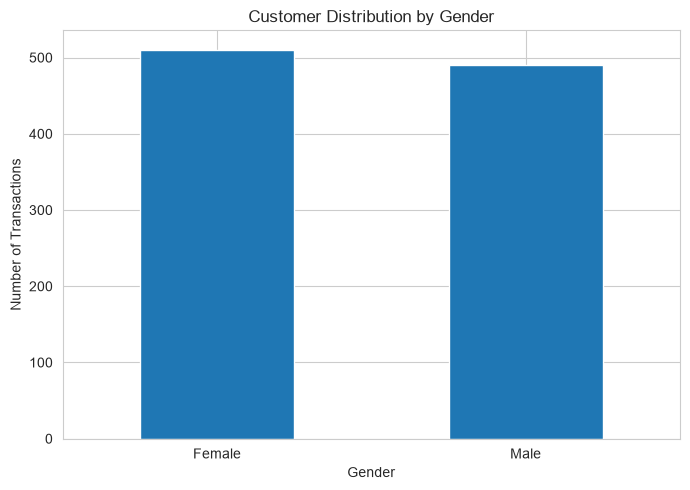

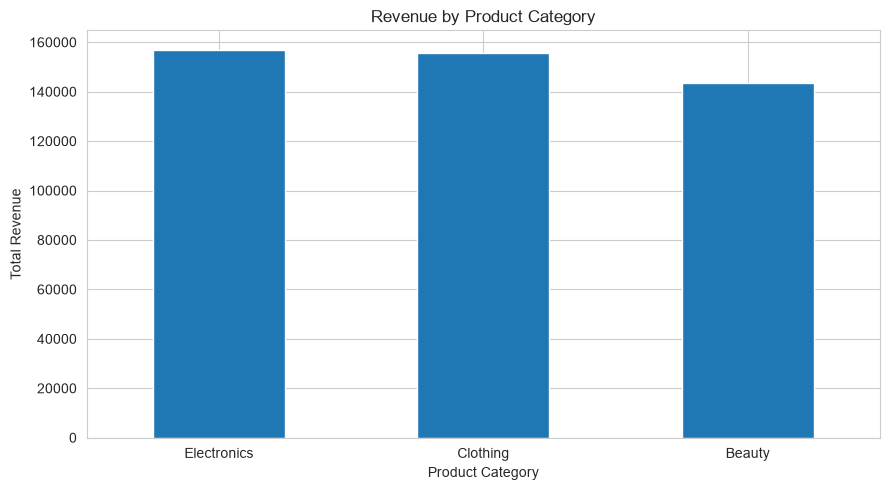

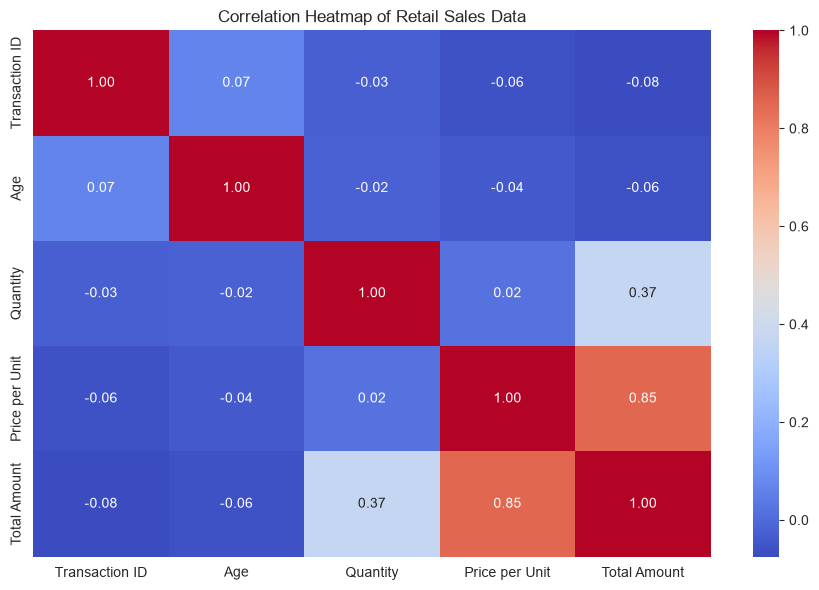

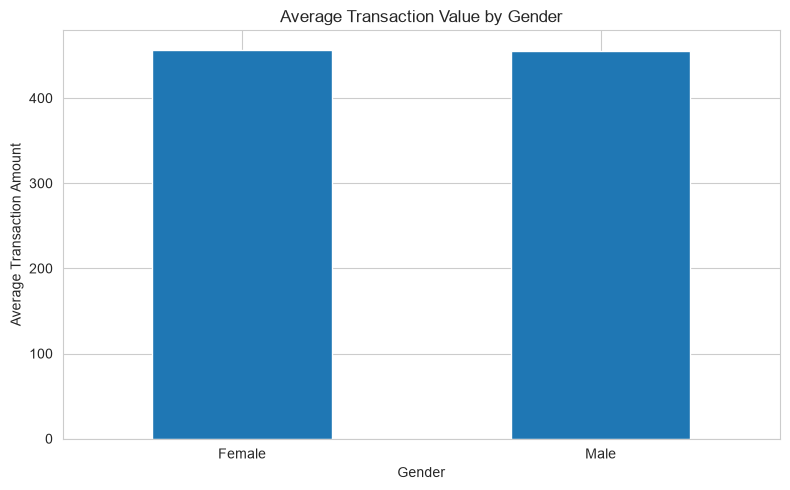

All graphs saved successfully in Output folder!


In [11]:

import os

# Create Output folder if it does not exist
os.makedirs("../Output", exist_ok=True)

# 1. Monthly Sales Trend
plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o')
plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("../Output/monthly_sales_trend.png", dpi=300)
plt.show()

# 2. Quarterly Sales Trend
plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind='line', marker='o')
plt.title('Quarterly Retail Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("../Output/quarterly_sales_trend.png", dpi=300)
plt.show()

# 3. Age Group Distribution
plt.figure(figsize=(9, 5))
age_distribution.plot(kind='bar')
plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../Output/age_group_distribution.png", dpi=300)
plt.show()

# 4. Gender Distribution
plt.figure(figsize=(7, 5))
gender_distribution.plot(kind='bar')
plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../Output/gender_distribution.png", dpi=300)
plt.show()

# 5. Category Revenue
plt.figure(figsize=(9, 5))
category_sales.sort_values(ascending=False).plot(kind='bar')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../Output/category_revenue.png", dpi=300)
plt.show()

# 6. Correlation Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Retail Sales Data')
plt.tight_layout()
plt.savefig("../Output/correlation_heatmap.png", dpi=300)
plt.show()

# 7. Average Transaction by Gender
plt.figure(figsize=(8, 5))
gender_sales.plot(kind='bar')
plt.title('Average Transaction Value by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../Output/average_transaction_gender.png", dpi=300)
plt.show()

print("All graphs saved successfully in Output folder!")


In [14]:

# Load Superstore Dataset

superstore = pd.read_csv(
    "../dataset/Sample - Superstore.csv",
    encoding="latin1"
)

# Display first 5 records
display(superstore.head())

# Check dataset shape
print("Dataset Shape:", superstore.shape)

# Check column names
print("\nColumn Names:")
print(superstore.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(superstore.isnull().sum())


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


TOP 10 BEST-SELLING PRODUCTS:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


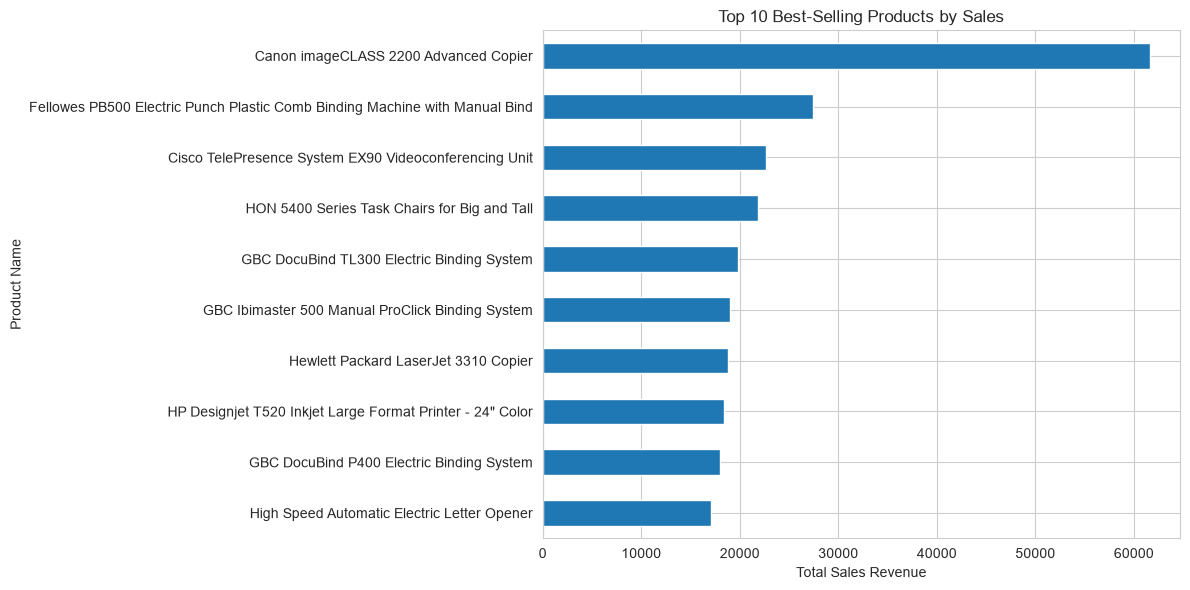

In [15]:

# Top 10 Best-Selling Products by Sales Revenue

top_10_products = (
    superstore.groupby('Product Name')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display Top 10 Products
print("TOP 10 BEST-SELLING PRODUCTS:")
print(top_10_products)

# Create visualization
plt.figure(figsize=(12, 6))

top_10_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products by Sales')
plt.xlabel('Total Sales Revenue')
plt.ylabel('Product Name')

plt.tight_layout()

# Save graph
plt.savefig(
    "../Output/top_10_best_selling_products.png",
    dpi=300
)

plt.show()


The top 10 best-selling products were identified
based on their total sales revenue using the
Sample Superstore dataset.

This analysis helps identify high-revenue products
and supports inventory and sales planning.

The top 10 best-selling products were identified
using total sales revenue from the Sample Superstore
dataset.

Canon imageCLASS 2200 Advanced Copier recorded the
highest sales revenue among the selected products.

This analysis helps businesses identify high-revenue
products and improve inventory planning.